In [1]:
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from openff.toolkit.topology import Molecule
from openff.toolkit.utils.toolkits import OpenEyeToolkitWrapper

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.molSize = (800, 400)   # Change image size
IPythonConsole.ipython_useSVG = True  # Change output to SVG

from matplotlib import colors
import matplotlib.cm as cm
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

In [2]:
class MyMolecule():
    def __init__(self, filename):
        
        self.filename = filename
        
        self.ext = filename.split('.')[-1]
        
        if self.ext == 'mol2':
            self.rdkit_mol = Chem.MolFromMol2File(filename, removeHs=False)
        else:
            raise TypeError('File type {} not implemented. File must be a mol2'.format(self.ext))
            
        self.n_atoms = len(self.rdkit_mol.GetAtoms())
        self.charges = np.zeros(self.n_atoms)
        
        self.SMILES = Chem.MolToSmiles(self.rdkit_mol)
        self.molecule = Molecule.from_smiles(self.SMILES)
        self.rdkit_mol = self.molecule.to_rdkit()
        self.names = [a.symbol + str(a.molecule_atom_index) for a in self.molecule.atoms]
    
    
    def write_charges(self, filename):
        
        np.savetxt(filename, self.charges, fmt='%.8f', delimiter=',')
        
        
    def read_charges(self, filename):
        
        charges = np.loadtxt(filename, delimiter=',')
        self.charges = charges
        
        return charges
    

    def assign_charges(self):

        toolkit_registry = OpenEyeToolkitWrapper()
        self.molecule.assign_partial_charges('am1bccelf10', toolkit_registry=toolkit_registry)
        self.charges = self.molecule.partial_charges.magnitude
    
    
    def display(self, show_charges=True, show_index=False, show_names=False, show_colorbar=True, size=(800,400)):
        
        if show_charges:
            for a, atom in enumerate(self.rdkit_mol.GetAtoms()):
                lbl = '%.4f'%(self.charges[a])
                atom.SetProp('atomNote',lbl)

        if show_index:
            for atom in self.rdkit_mol.GetAtoms():
                atom.SetAtomMapNum(atom.GetIdx()+1)
                
        # if show_names:
        #     for a, atom in enumerate(self.rdkit_mol.GetAtoms()):
        #         lbl = f'{self.names[a]}'
        #         atom.SetAtomMapNum(lbl)
        
        # Create a colormap on charges
        cmap = cm.coolwarm
        charge_max = max(self.charges.max(), -self.charges.min())

        norm = colors.Normalize(vmin=-charge_max, vmax=charge_max, clip=True)
        mapper = cm.ScalarMappable(norm=norm, cmap=cmap)

        cs = {}
        atom_set = []
        for i in range(self.n_atoms):
            c = mapper.to_rgba(self.charges[i])
            cs[i] = c
            atom_set.append(i)

        if show_colorbar:
            fig, ax = plt.subplots(1,1, figsize=(10,1))
            ax.axis('off')
            cbar = plt.colorbar(mapper, orientation='horizontal', location='top', fraction=1, label='Charges', ax=ax)

        # draw molecule with atoms colored by charge difference
        drawer = rdMolDraw2D.MolDraw2DSVG(size[0], size[1])
        drawer.drawOptions().useBWAtomPalette()
        drawer.DrawMolecule(self.rdkit_mol, highlightAtoms=atom_set, highlightBonds=[], highlightAtomColors=cs)
        drawer.FinishDrawing()
        svg = drawer.GetDrawingText().replace('svg:','')
        display(SVG(svg))

        return svg
    
    

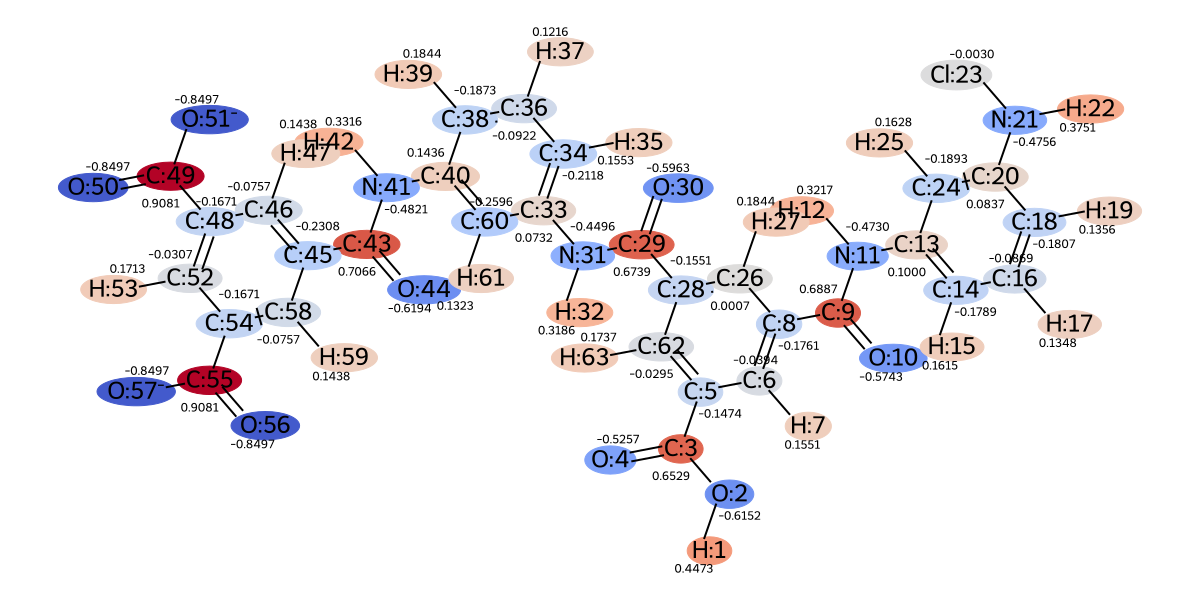

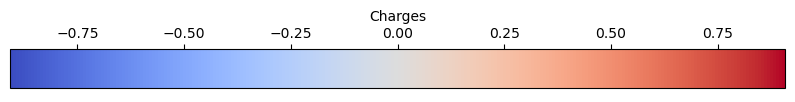

In [3]:
mol = MyMolecule('./2MPD_2TMC_1P_Cl/2MPD_2TMC_1P_Cl.mol2')
# mol.assign_charges()
# mol.write_charges('./2MPD_2TMC_1P_Cl/am1bccelf10.csv')
mol.read_charges('./2MPD_2TMC_1P_Cl/am1bccelf10.csv')
svg = mol.display(show_index=True, size=(1200,600))

In [4]:
mol.charges[10:25]

array([-0.47303   ,  0.32166001,  0.1       , -0.17895   ,  0.16152   ,
       -0.08695   ,  0.1348    , -0.18073   ,  0.13561   ,  0.08374   ,
       -0.47558999,  0.37507999, -0.00303   , -0.18929001,  0.16277   ])

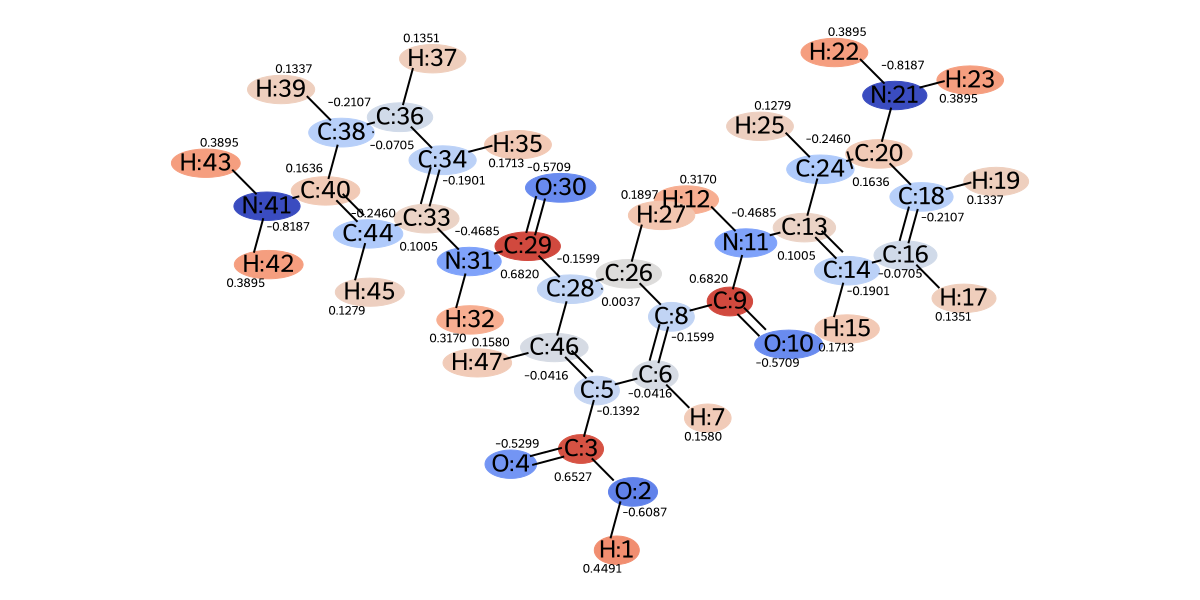

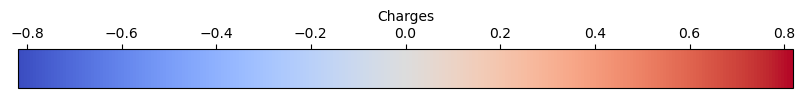

In [5]:
mol1 = MyMolecule('./2MPD_1TMC_1P/2MPD_1TMC_1P.mol2')
# mol1.assign_charges()
# mol1.write_charges('./2MPD_1TMC_1P/am1bccelf10.csv')
mol1.read_charges('./2MPD_1TMC_1P/am1bccelf10.csv')
svg = mol1.display(show_index=True, size=(1200,600))

In [19]:
print('Total charge on MPD-T-Cl:', mol.charges[10:25].sum())
mol_nh = mol.charges[20]
mol_hn = mol.charges[21]
mol_cl = mol.charges[22]
print('Chlorinated amine (NHCl) charge:', mol_nh + mol_hn + mol_cl)

print('\nTotal charge on MPD-T:', mol1.charges[10:25].sum())
mol1_nh = mol1.charges[20]
mol1_hna = mol1.charges[21]
mol1_hnb = mol1.charges[22]
print('Amine (NH2) charge:', mol1_nh + mol1_hna + mol1_hnb)

diff = mol.charges[10:25].sum() - mol1.charges[10:25].sum()
print('\nDifference in total charge (MPD-T-Cl - MPD-T):', diff)

Total charge on MPD-T-Cl: -0.11239000000000007
Chlorinated amine (NHCl) charge: -0.10354000000000005

Total charge on MPD-T: -0.07632998000000005
Amine (NH2) charge: -0.03974001000000005

Difference in total charge (MPD-T-Cl - MPD-T): -0.036060020000000026


## get charges for possible monomers that formed during chlorination

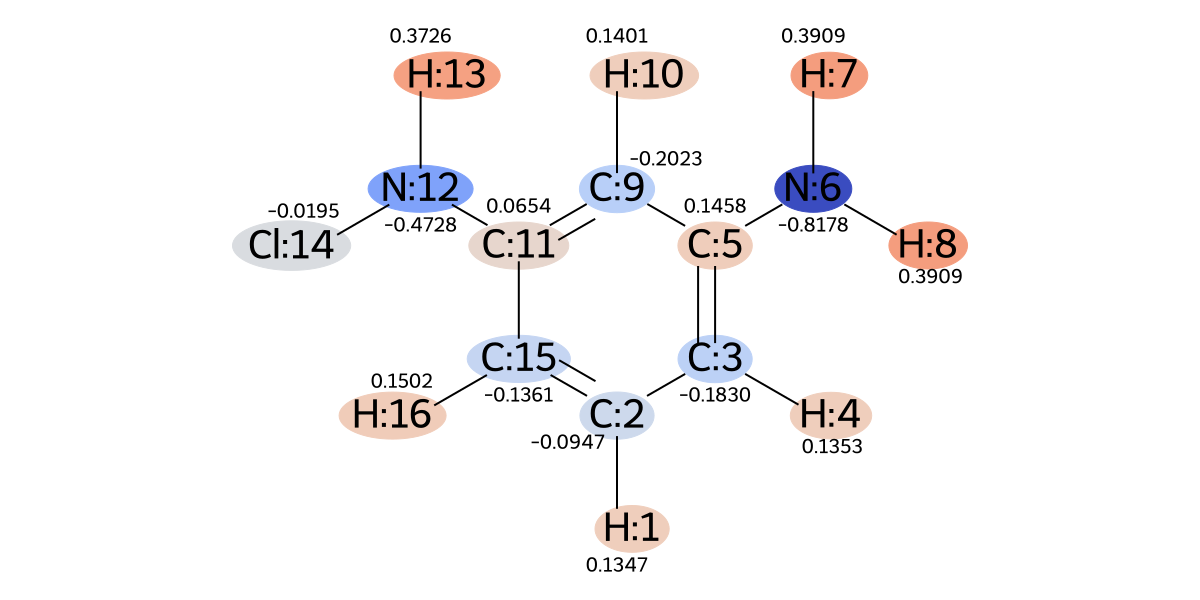

array([ 0.13471   , -0.09465   , -0.18303999,  0.13529999,  0.14582001,
       -0.81778997,  0.39089998,  0.39089998, -0.20227   ,  0.14013   ,
        0.06542   , -0.47275999,  0.37261   , -0.01946   , -0.13605   ,
        0.15023   ])

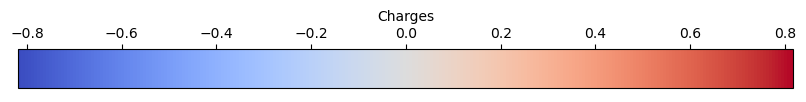

In [10]:
name = 'MPD_Cl'
mol = MyMolecule(f'./{name}/{name}.mol2')
mol.assign_charges()
mol.write_charges(f'./{name}/am1bccelf10.csv')
# mol.read_charges(f'./{name}/am1bccelf10.csv')
svg = mol.display(show_index=True, size=(1200,600))
mol.charges

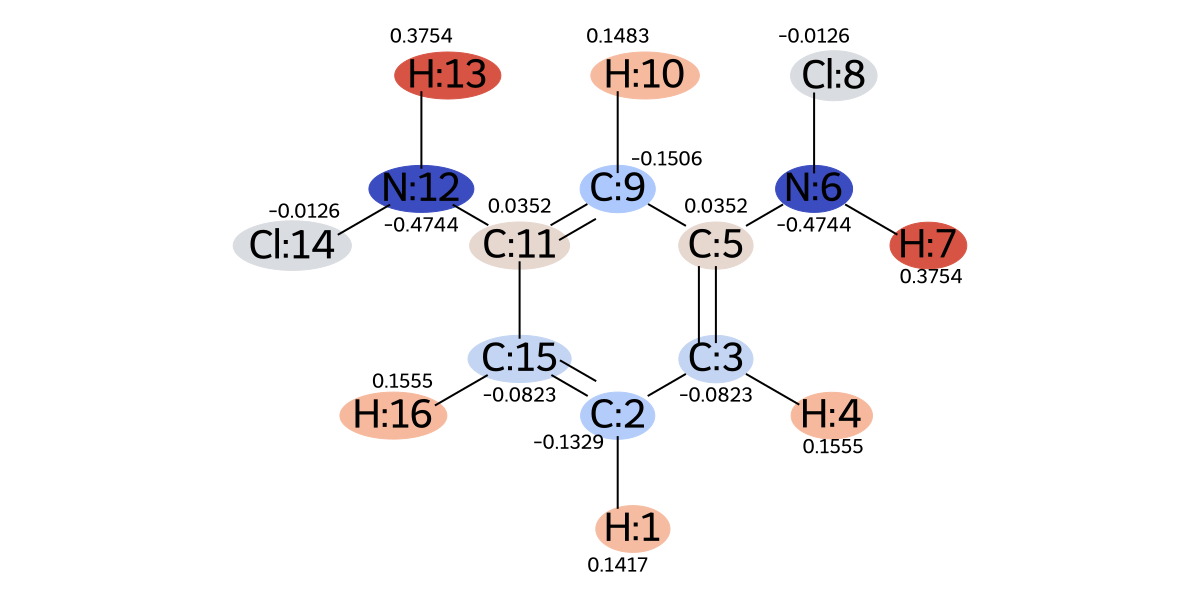

array([ 0.14171, -0.13287, -0.08234,  0.15547,  0.03518, -0.47439,
        0.37542, -0.01257, -0.15064,  0.14826,  0.03518, -0.47439,
        0.37542, -0.01257, -0.08234,  0.15547])

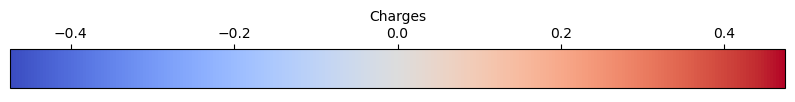

In [11]:
name = 'MPD_2Cl'
mol = MyMolecule(f'./{name}/{name}.mol2')
mol.assign_charges()
mol.write_charges(f'./{name}/am1bccelf10.csv')
# mol.read_charges(f'./{name}/am1bccelf10.csv')
svg = mol.display(show_index=True, size=(1200,600))
mol.charges

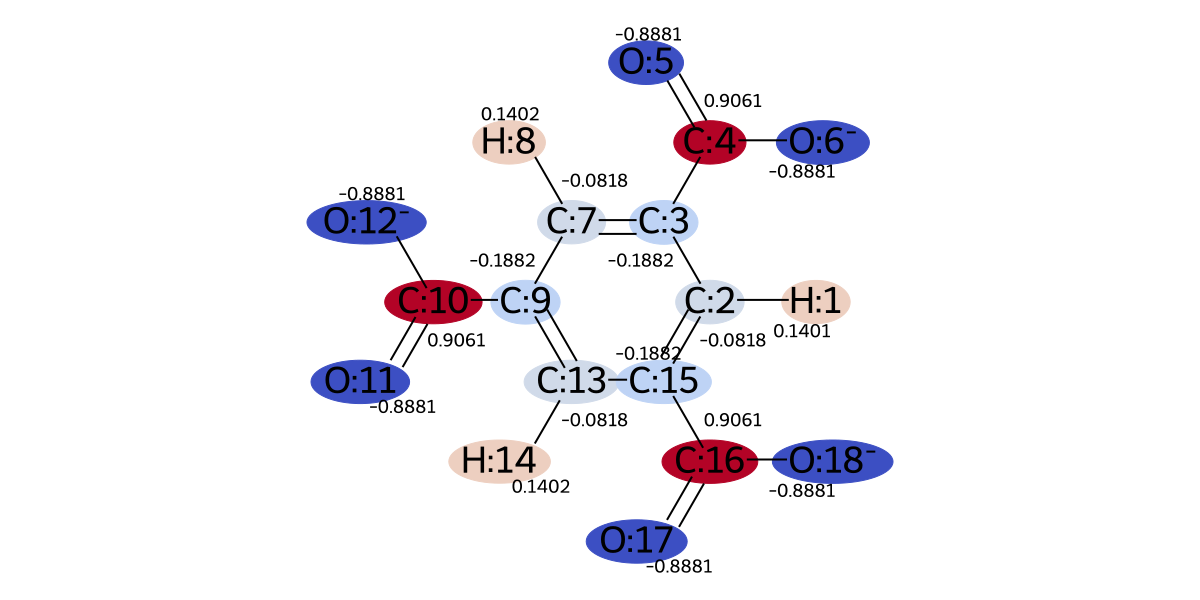

array([ 0.14014999, -0.08180001, -0.18822   ,  0.90610998, -0.88814998,
       -0.88814998, -0.08180001,  0.14023999, -0.18822   ,  0.90610998,
       -0.88814998, -0.88814998, -0.08180001,  0.14023999, -0.18822   ,
        0.90610998, -0.88814998, -0.88814998])

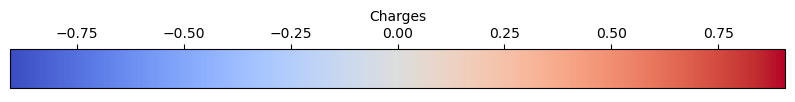

In [12]:
name = 'TMC_0P'
mol = MyMolecule(f'./{name}/{name}.mol2')
mol.assign_charges()
mol.write_charges(f'./{name}/am1bccelf10.csv')
# mol.read_charges(f'./{name}/am1bccelf10.csv')
svg = mol.display(show_index=True, size=(1200,600))
mol.charges

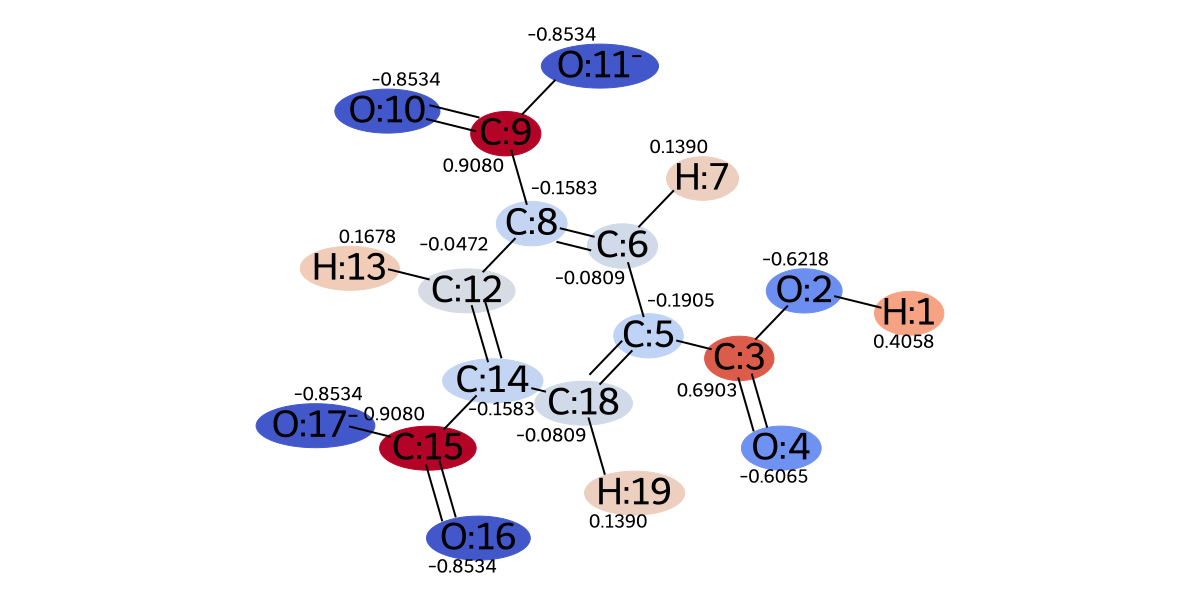

array([ 0.40584   , -0.62176002,  0.69033998, -0.60645998, -0.19048   ,
       -0.08092001,  0.13898   , -0.15832   ,  0.90799999, -0.85338998,
       -0.85338998, -0.04718001,  0.16777999, -0.15832   ,  0.90799999,
       -0.85338998, -0.85338998, -0.08092001,  0.13898   ])

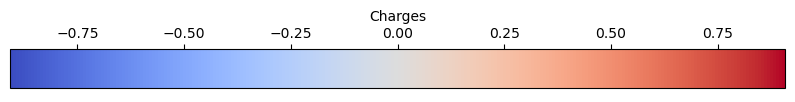

In [13]:
name = 'TMC_1P'
mol = MyMolecule(f'./{name}/{name}.mol2')
mol.assign_charges()
mol.write_charges(f'./{name}/am1bccelf10.csv')
# mol.read_charges(f'./{name}/am1bccelf10.csv')
svg = mol.display(show_index=True, size=(1200,600))
mol.charges

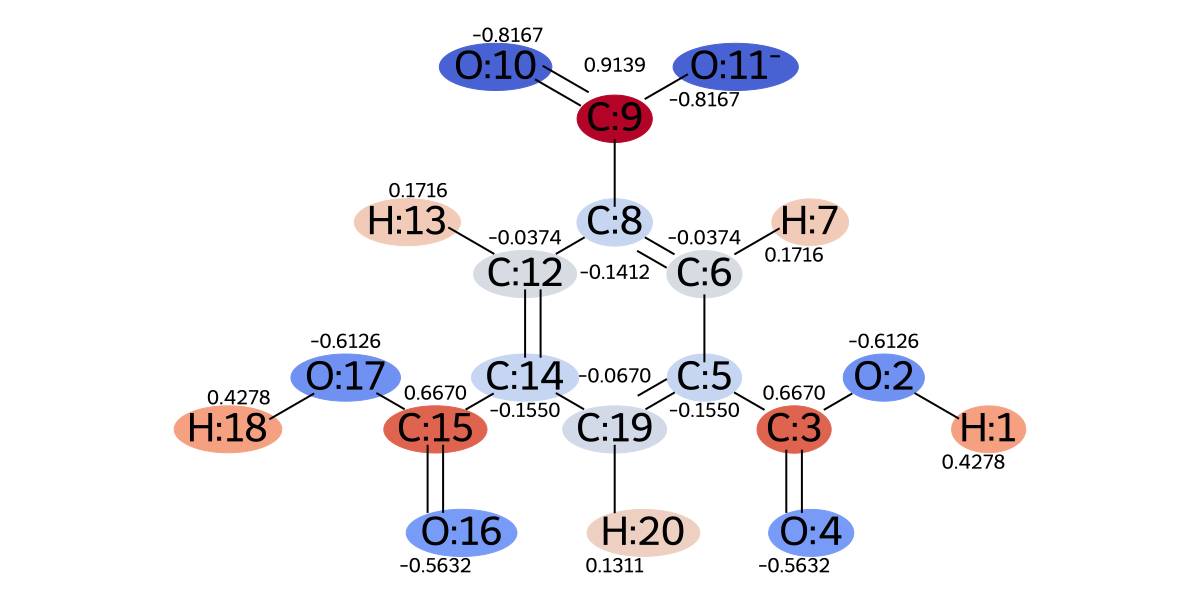

array([ 0.42783001, -0.61258   ,  0.667     , -0.56321001, -0.15498   ,
       -0.03738   ,  0.1716    , -0.14125   ,  0.91391999, -0.81665999,
       -0.81665999, -0.03738   ,  0.1716    , -0.15498   ,  0.667     ,
       -0.56321001, -0.61258   ,  0.42783001, -0.067     ,  0.13109   ])

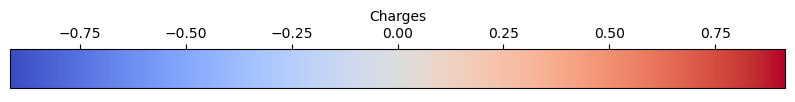

In [14]:
name = 'TMC_2P'
mol = MyMolecule(f'./{name}/{name}.mol2')
mol.assign_charges()
mol.write_charges(f'./{name}/am1bccelf10.csv')
# mol.read_charges(f'./{name}/am1bccelf10.csv')
svg = mol.display(show_index=True, size=(1200,600))
mol.charges

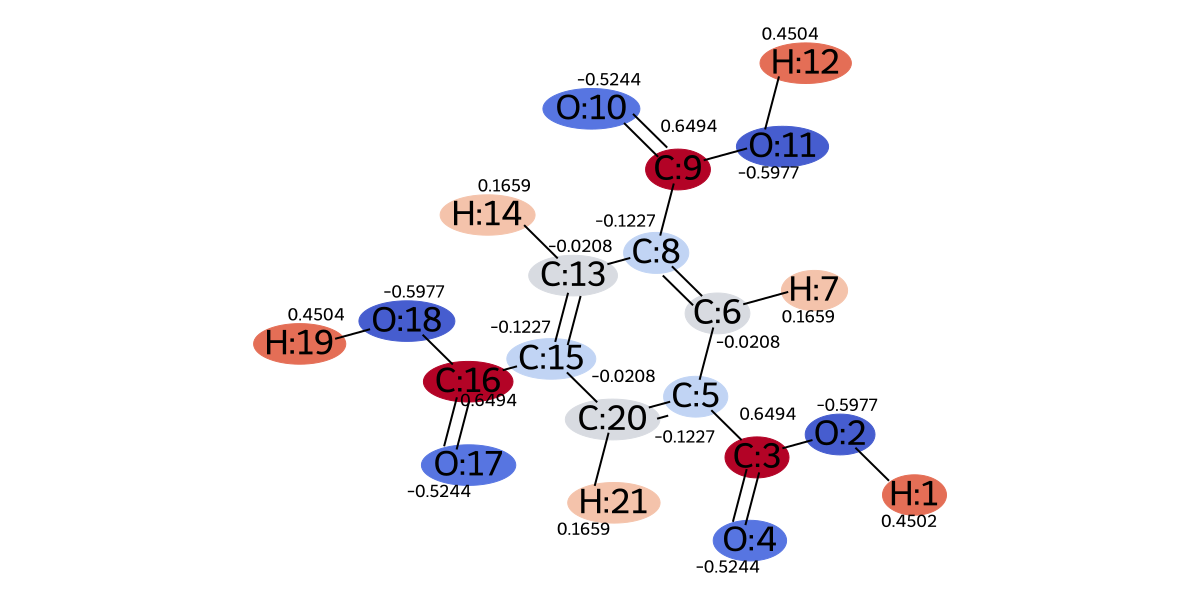

array([ 0.45023999, -0.59766001,  0.64937001, -0.5244    , -0.12272   ,
       -0.02081   ,  0.16587999, -0.12272   ,  0.64937001, -0.5244    ,
       -0.59766001,  0.45039001, -0.02081   ,  0.16587999, -0.12272   ,
        0.64937001, -0.5244    , -0.59766001,  0.45039001, -0.02081   ,
        0.16587999])

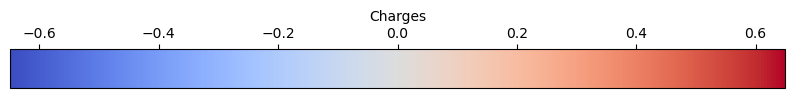

In [15]:
name = 'TMC_3P'
mol = MyMolecule(f'./{name}/{name}.mol2')
mol.assign_charges()
mol.write_charges(f'./{name}/am1bccelf10.csv')
# mol.read_charges(f'./{name}/am1bccelf10.csv')
svg = mol.display(show_index=True, size=(1200,600))
mol.charges